In [2]:
import os
from pathlib import Path
if not (Path.cwd() / "Risk_Modeling").exists():
    os.chdir("..")


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from Shared_Utils.Data_Utils import load_data, remove_sparse_tickers
from Risk_Modeling.Risk_Kit.Factor_Risk_Model import risk
from Risk_Modeling.Risk_Kit.Risk_Kit_Utils.Risk_Model_Harness import multiple_model_tracker,run_multiple_risk_models


%load_ext autoreload
%autoreload 2

In [3]:
def random_long_portfolio(n_assets,current_data):
    portfolio=current_data[["Date","Ticker","PCT_Return"]]
    hypothetical_weight=np.random.rand(len(current_data))
    selected_weight = np.zeros_like(hypothetical_weight)
    idx = np.random.choice(len(hypothetical_weight), size=n_assets, replace=False)
    selected_weight[idx] = hypothetical_weight[idx]
    portfolio["Weight"]=selected_weight/selected_weight.sum()
    
    individual_return=portfolio["Weight"]*portfolio["PCT_Return"]
    realized_return=float(individual_return.sum())
    portfolio.drop("Weight",axis=1)
    return portfolio, realized_return

# Risk Modeling

In [4]:
df=load_data()
all_dates=df["Date"].unique()

In [41]:
models_dict={

            "Basic model":risk(),
            **{f"Basic model {i} month halflife": risk(ewma_halflife=i) for i in range(1, 13)},

            "Fundamental factor model":risk(fundamental_factor_model=True),
            **{f"Fundamental factor model {i} month halflife": risk(fundamental_factor_model=True, ewma_halflife=i) for i in range(1, 13)},

            "PCA factor model":risk(pca_factor_model=True),
            **{f"PCA factor model {i} month halflife": risk(pca_factor_model=True, ewma_halflife=i) for i in range(1, 13)},

            "Ledoit-wolf model":risk(ledoit_wolf=True),
            **{f"Ledoit-wolf model {i} month halflife": risk(ledoit_wolf=True, ewma_halflife=i) for i in range(1, 13)},

            "Fundamental factor model Ledoit-Wolf":risk(fundamental_factor_model=True,ledoit_wolf=True),
            **{f"Fundamental factor model Ledoit-Wolf {i} month halflife": risk(fundamental_factor_model=True, ledoit_wolf=True, ewma_halflife=i) for i in range(1, 13)},

            "PCA factor model Ledoit-Wolf":risk(pca_factor_model=True,ledoit_wolf=True),
            **{f"PCA factor model Ledoit-Wolf {i} month halflife": risk(pca_factor_model=True, ledoit_wolf=True, ewma_halflife=i) for i in range(1, 13)},
}


n_assets=[400,200,100,50,20,10] #number of assets in each random portfolio
trackers={n:multiple_model_tracker(models_dict) for n in n_assets}

seed_number=1
lookback=60
for i, date in enumerate(all_dates):
    print(f"\r{date}", end="", flush=True)
    if i<lookback:
        continue

    # Select historical PIT data 
    historical_data=df[(df["Date"]<date) & (df["Date"]>=all_dates[i-lookback])]
    historical_data,valid_tickers=remove_sparse_tickers(historical_data)
    average_return=historical_data.pivot(index="Date",columns="Ticker",values="PCT_Return").mean()
    average_return.name="AVG_Return"
    
    # Run risk models on historical data
    models_dict=run_multiple_risk_models(models_dict,historical_data)
    # Identify current data
    current_data=df[df["Date"]==date]
    current_data=current_data[current_data["Ticker"].isin(valid_tickers)]

    
    for n in n_assets:
        #Create a random diversified portfolio
        np.random.seed(seed_number);seed_number+=1
        portfolio,realized_return=random_long_portfolio(n,current_data)

        
        excess_portfolio=portfolio[["Ticker","Weight","PCT_Return"]].merge(average_return,on="Ticker",how="left")
        excess_portfolio["Excess_return"]=excess_portfolio["PCT_Return"]-excess_portfolio["AVG_Return"]
        excess_return=(excess_portfolio["Excess_return"]*excess_portfolio["Weight"]).sum()

        # Update tracking
        trackers[n].append_multiple_variance_estimates(date,models_dict,current_data,portfolio)
        trackers[n].append_multiple_realized_systematic_returns(date,models_dict,current_data,portfolio)
        trackers[n].append_realized_return(date,realized_return)
        trackers[n].append_excess_return(date,excess_return)

2025-12-31 00:00:00

# Results

In [51]:
for n in n_assets:
    print(f"Performance Summary for Portfolio with {n} Assets:")
    with pd.option_context('display.max_rows', None):
        perf_df=trackers[n].performance_summary(models_dict)
        perf_df["Miscalibration"]=np.abs(perf_df["Mean Z Squared"]-1)
        perf_df=perf_df.sort_values(by="Miscalibration").drop(columns="Miscalibration")
        display(perf_df)
    print("\n")

Performance Summary for Portfolio with 400 Assets:


,Mean Z,Standard Deviation Z,Mean Z Squared,Kurtosis,Normality P-Value
Ledoit-wolf model 12 month halflife,-0.057341,1.006824,1.000088,-0.339841,3.554370e-01
Fundamental factor model Ledoit-Wolf 6 month halflife,-0.071746,1.010890,1.010014,-0.302335,2.187583e-01
Fundamental factor model 2 month halflife,-0.068387,1.021488,1.030724,-0.339994,4.501004e-01
Ledoit-wolf model 11 month halflife,-0.060666,1.025293,1.037386,-0.302465,3.272945e-01
Basic model 2 month halflife,-0.065329,1.025035,1.037452,-0.389177,5.107317e-01
Fundamental factor model Ledoit-Wolf 7 month halflife,-0.066282,0.975444,0.940025,-0.334592,2.667352e-01
Basic model 3 month halflife,-0.063874,0.974605,0.938105,-0.329870,3.472023e-01
Fundamental factor model 3 month halflife,-0.067195,0.969934,0.929608,-0.294720,2.905606e-01
Ledoit-wolf model 10 month halflife,-0.064964,1.049513,1.087339,-0.249268,2.909157e-01
Fundamental factor model Ledoit-Wolf 8 month halflife,-0.062094,0.950449,0.892153,-0.366697,3.052340e-01




Performance Summary for Portfolio with 200 Assets:


,Mean Z,Standard Deviation Z,Mean Z Squared,Kurtosis,Normality P-Value
Fundamental factor model Ledoit-Wolf 6 month halflife,-0.061725,1.007826,1.002596,-0.329284,0.489655
Ledoit-wolf model 12 month halflife,-0.048150,1.002538,0.990649,-0.212683,0.584268
Basic model 2 month halflife,-0.063376,1.011930,1.010952,-0.410140,0.325971
Fundamental factor model 2 month halflife,-0.065156,1.012311,1.011939,-0.381925,0.404349
Ledoit-wolf model 11 month halflife,-0.051848,1.020829,1.027413,-0.180739,0.537101
Fundamental factor model Ledoit-Wolf 7 month halflife,-0.055937,0.974548,0.937044,-0.345128,0.529263
Ledoit-wolf model 10 month halflife,-0.056576,1.044699,1.076407,-0.135694,0.473787
Basic model 3 month halflife,-0.060034,0.966350,0.921872,-0.314654,0.347687
Fundamental factor model 3 month halflife,-0.061986,0.966186,0.921798,-0.313472,0.355095
Fundamental factor model Ledoit-Wolf 5 month halflife,-0.069481,1.057480,1.104454,-0.327340,0.461056




Performance Summary for Portfolio with 100 Assets:


,Mean Z,Standard Deviation Z,Mean Z Squared,Kurtosis,Normality P-Value
Ledoit-wolf model 12 month halflife,-0.082518,1.016792,1.023443,-0.441864,0.463636
Fundamental factor model Ledoit-Wolf 6 month halflife,-0.082800,1.019468,1.028849,-0.495286,0.566438
Fundamental factor model 2 month halflife,-0.085425,1.020732,1.031826,-0.587643,0.512776
Fundamental factor model Ledoit-Wolf 7 month halflife,-0.076890,0.988360,0.966486,-0.494047,0.600207
Basic model 3 month halflife,-0.092868,0.980987,0.954922,-0.520224,0.344480
Fundamental factor model 3 month halflife,-0.081859,0.975065,0.941607,-0.534713,0.431904
Ledoit-wolf model 11 month halflife,-0.086094,1.033968,1.058683,-0.418325,0.447981
Basic model 2 month halflife,-0.099142,1.037502,1.068300,-0.498355,0.570806
Fundamental factor model Ledoit-Wolf 8 month halflife,-0.072399,0.966344,0.923499,-0.497693,0.627419
Ledoit-wolf model 10 month halflife,-0.090715,1.056299,1.105401,-0.384734,0.428070


... (2 outputs left out)



Performance Summary for Portfolio with 20 Assets:


,Mean Z,Standard Deviation Z,Mean Z Squared,Kurtosis,Normality P-Value
Ledoit-wolf model 7 month halflife,-0.122628,0.995937,0.990397,0.471085,0.145679
Fundamental factor model Ledoit-Wolf 3 month halflife,-0.097113,1.012771,1.018040,0.224526,0.225628
Basic model 1 month halflife,-0.142409,1.023659,1.050693,0.410820,0.441979
Fundamental factor model 1 month halflife,-0.093655,0.967751,0.929704,0.181763,0.587596
Ledoit-wolf model 8 month halflife,-0.114067,0.955657,0.911070,0.300377,0.165662
Ledoit-wolf model 6 month halflife,-0.132324,1.052158,1.106096,0.655266,0.146296
Fundamental factor model Ledoit-Wolf 4 month halflife,-0.102613,0.945670,0.889916,0.369977,0.174650
Ledoit-wolf model 9 month halflife,-0.107133,0.926368,0.855333,0.170987,0.181594
Ledoit-wolf model 10 month halflife,-0.101628,0.904679,0.815132,0.078300,0.190250
Basic model 2 month halflife,-0.115882,0.898831,0.807861,0.141824,0.345710




Performance Summary for Portfolio with 10 Assets:


,Mean Z,Standard Deviation Z,Mean Z Squared,Kurtosis,Normality P-Value
Ledoit-wolf model,0.063019,1.008735,1.004559,-0.497659,0.796425
Basic model 5 month halflife,0.036441,1.000611,0.985864,-0.360927,0.556813
Fundamental factor model Ledoit-Wolf 5 month halflife,0.057104,1.014866,1.016048,0.021963,0.609869
Fundamental factor model 3 month halflife,0.047529,0.993815,0.973466,-0.119311,0.629505
Basic model 4 month halflife,0.034289,1.023748,1.031768,-0.276052,0.506409
Fundamental factor model Ledoit-Wolf 6 month halflife,0.054811,0.989343,0.965491,-0.032010,0.667171
Fundamental factor model 2 month halflife,0.049402,1.028017,1.041646,-0.144213,0.630482
Basic model 6 month halflife,0.038773,0.983630,0.952905,-0.423953,0.599490
Basic model 7 month halflife,0.040943,0.971019,0.928840,-0.469098,0.622945
Fundamental factor model Ledoit-Wolf 7 month halflife,0.053730,0.969965,0.928039,-0.073724,0.685899


In [29]:
def plot_volatility_estimates(tracker,models_dict,number_of_assets):
    vol_cloud=[]
    for i,model in enumerate(models_dict):
        vol=pd.DataFrame(tracker.variance_estimates[model]).iloc[0]
        vol.name=model
        vol_cloud.append(vol)
    vol_cloud=pd.concat(vol_cloud,axis=1)
    cmap = plt.colormaps['tab20']
    plt.figure(figsize=(15, 9))
    colors = [cmap(i / (len(models_dict)+1 - 1)) for i in range(len(models_dict)+1)]
    for i,col in enumerate(vol_cloud):
        plt.plot(vol_cloud[col],color=colors[i],label=col,marker='o')
    plt.plot(pd.DataFrame(tracker.realized_returns).iloc[0]**2,color=colors[i+1],label="Realized Return",marker='o')
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.title(f"Variance Estimates for Portfolio with {number_of_assets} Assets")
    plt.tight_layout()
    plt.show()

In [48]:
models_of_interest={}
models_of_interest["Fundamental factor model Ledoit-Wolf 6 month halflife"]=models_dict["Fundamental factor model Ledoit-Wolf 6 month halflife"]
models_of_interest["Ledoit-wolf model 12 month halflife"]=models_dict["Ledoit-wolf model 12 month halflife"]
models_of_interest

{'Fundamental factor model Ledoit-Wolf 6 month halflife': <Risk_Modeling.Risk_Kit.Factor_Risk_Model.risk at 0x200a1bcc310>,
 'Ledoit-wolf model 12 month halflife': <Risk_Modeling.Risk_Kit.Factor_Risk_Model.risk at 0x200a2027d80>}

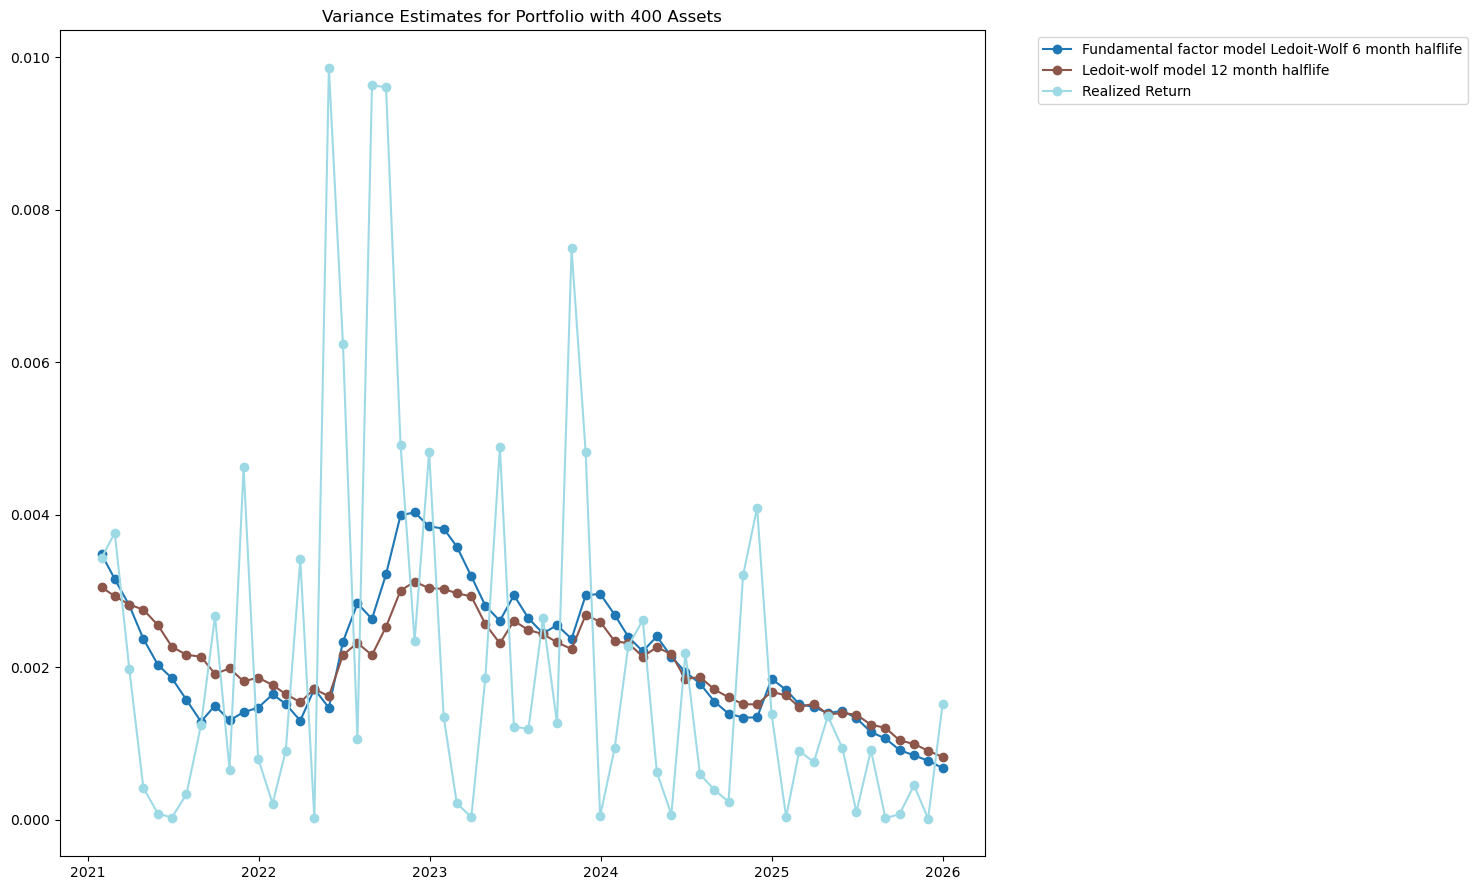

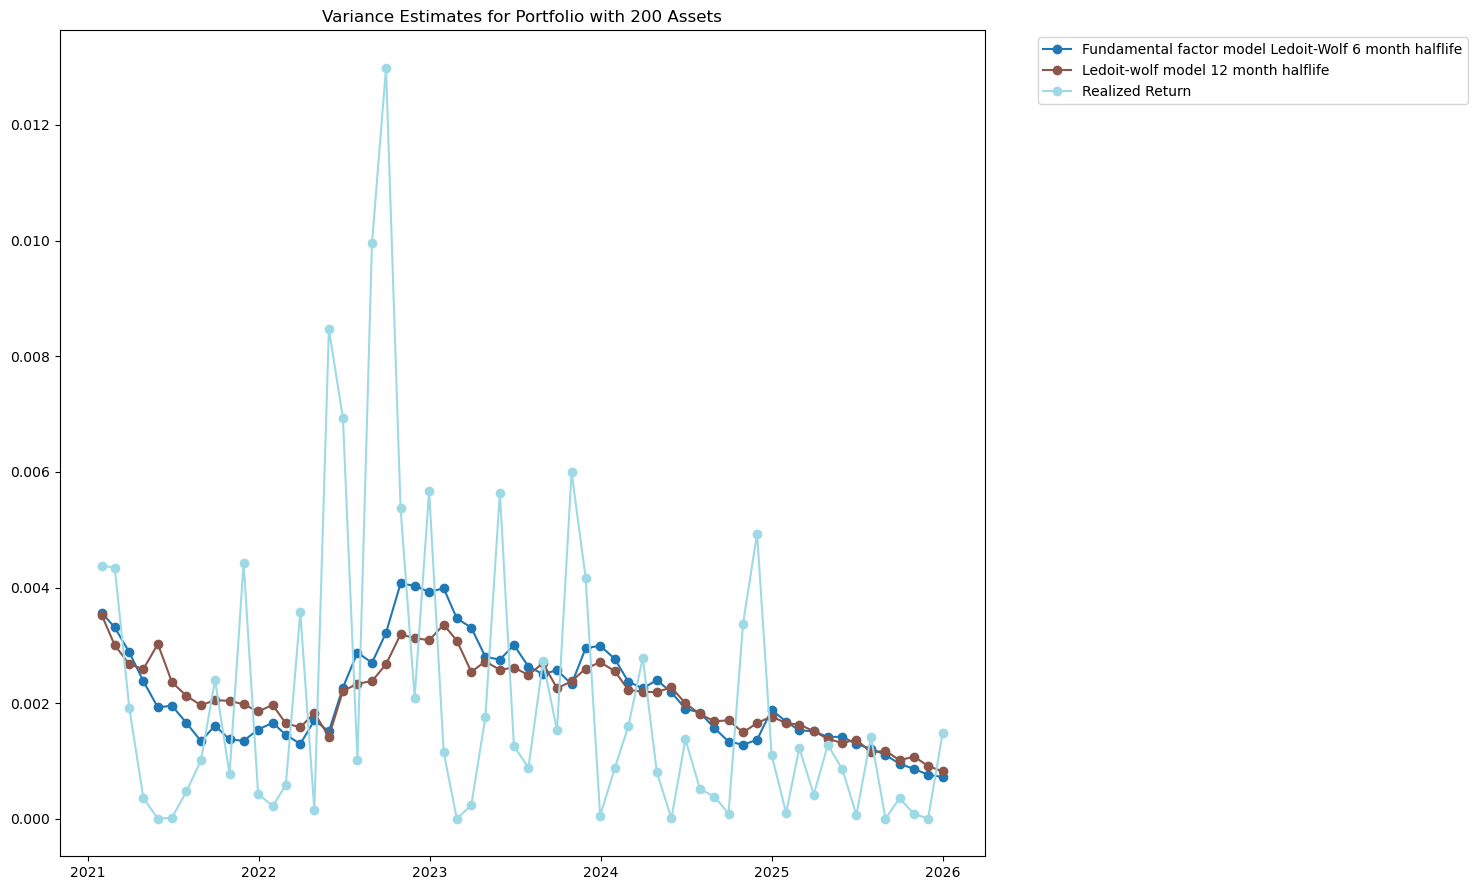

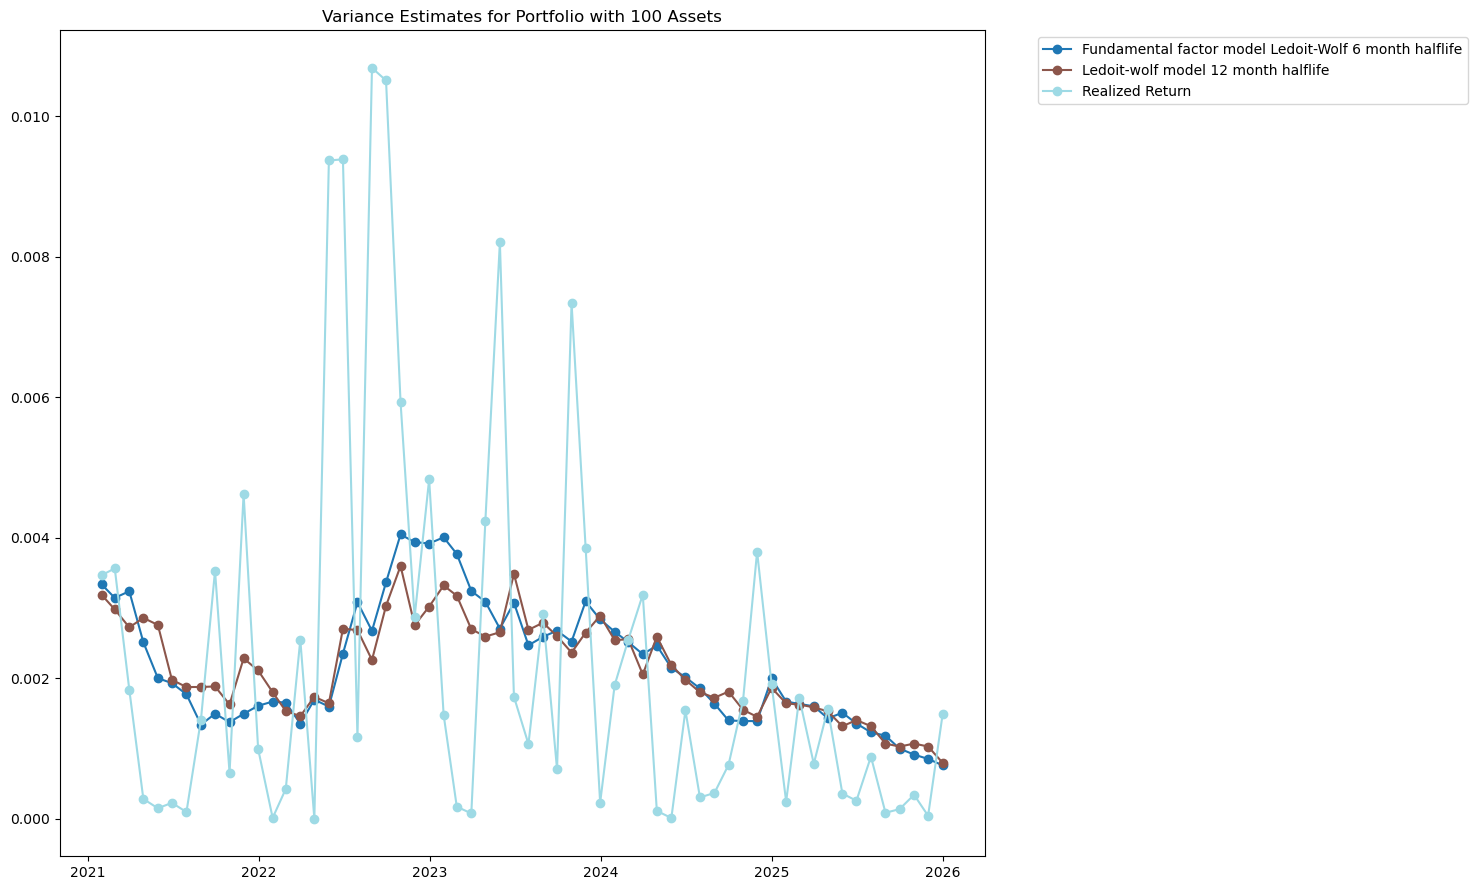

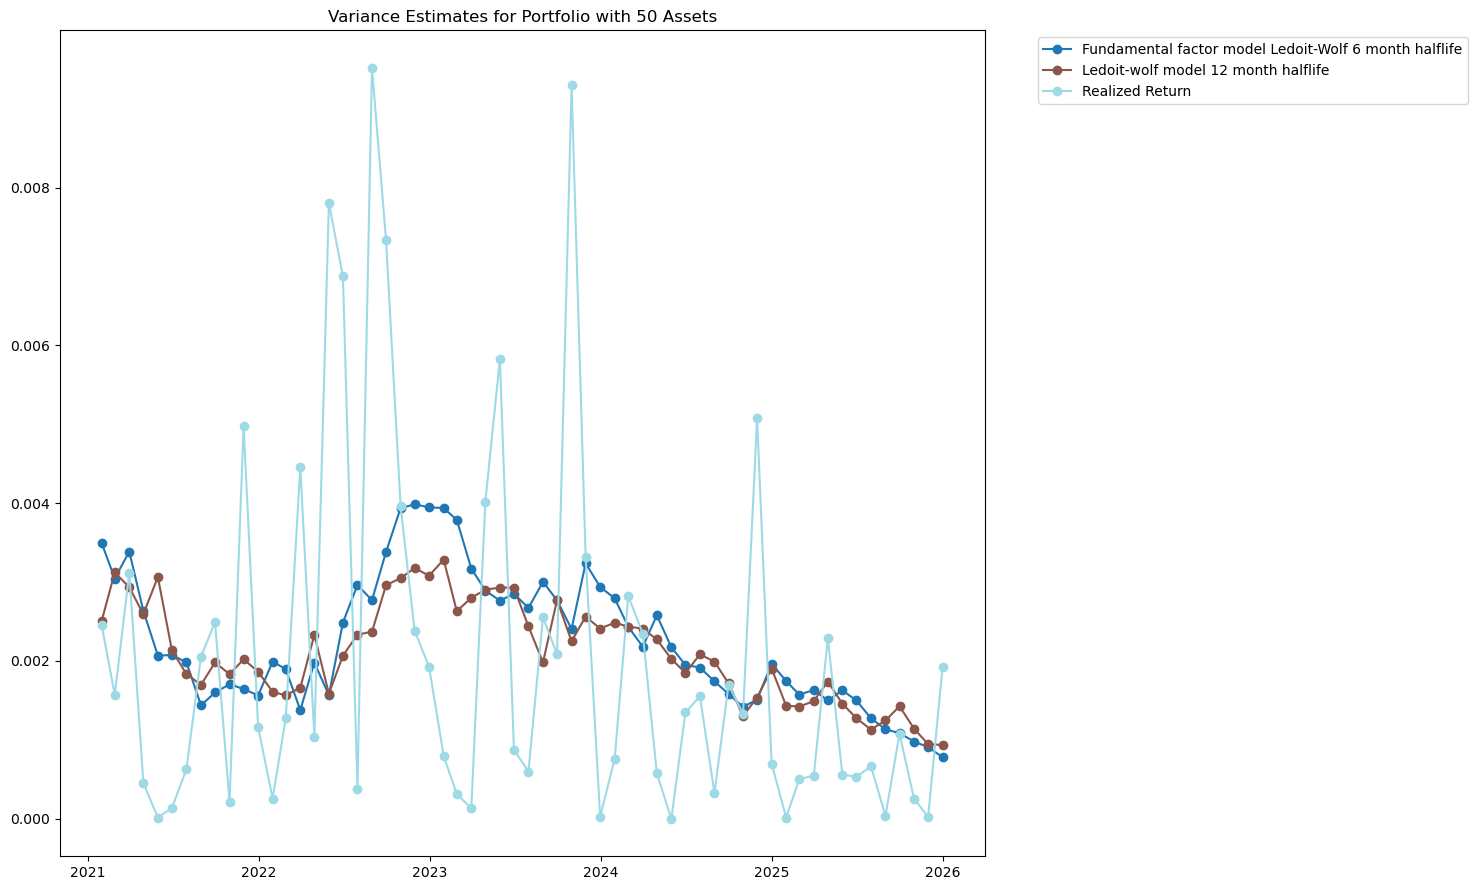

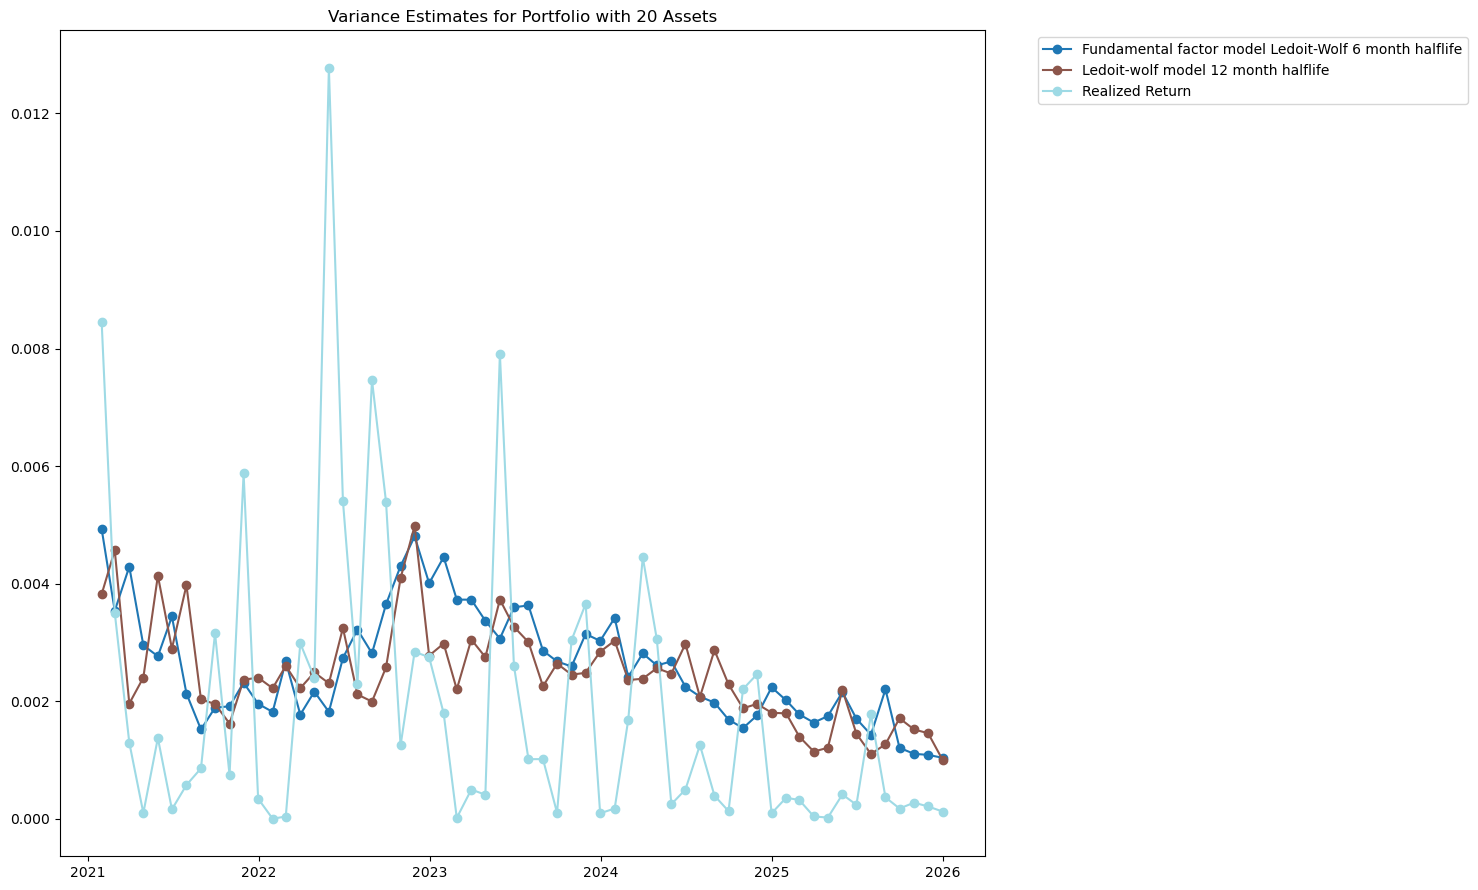

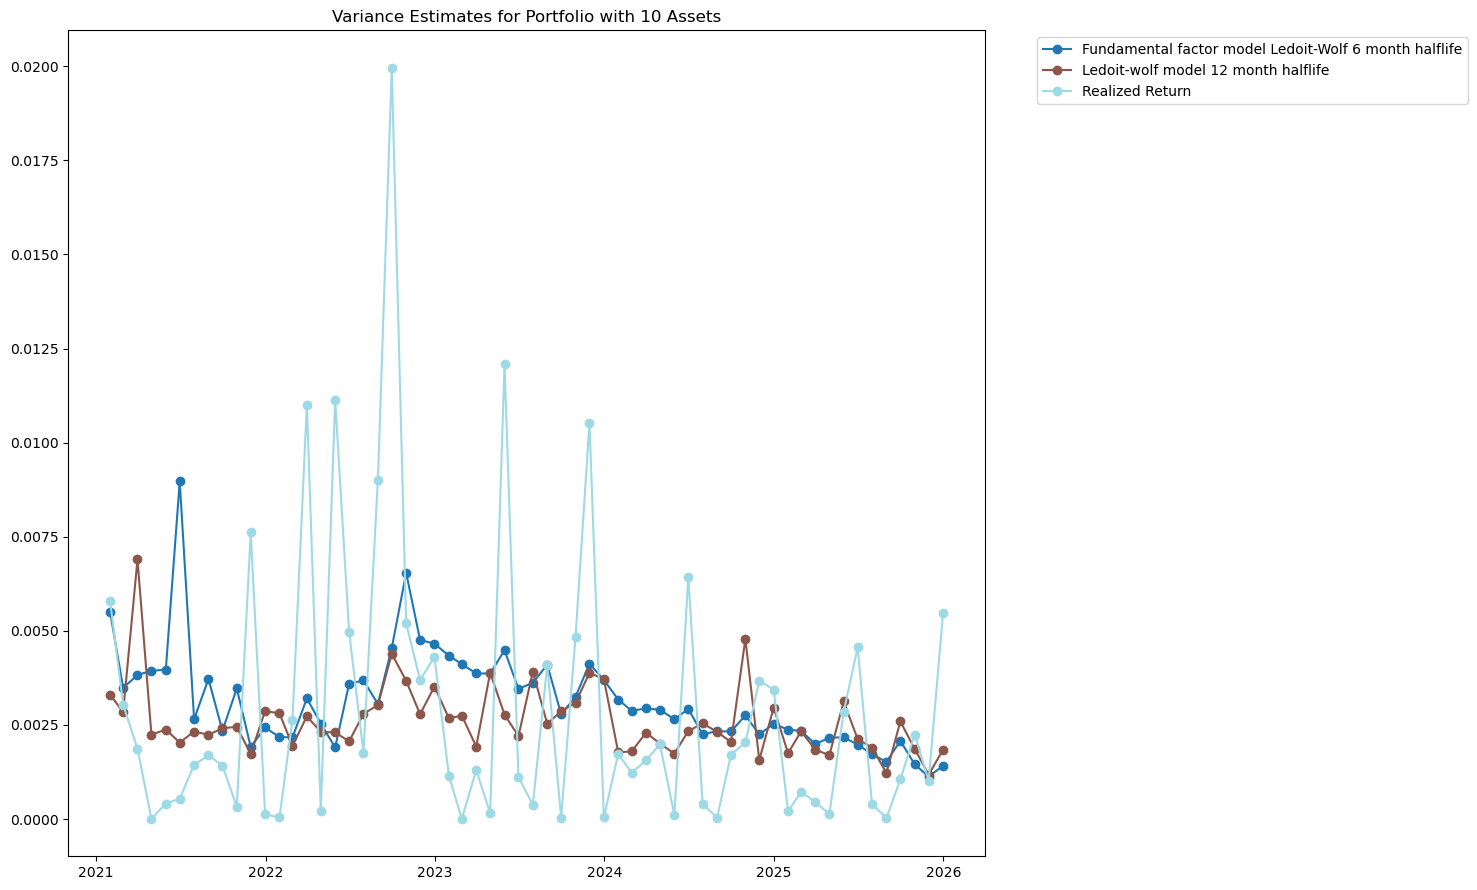

In [49]:
for n in n_assets:
    plot_volatility_estimates(trackers[n],models_of_interest,n)
    print("\n")